In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
import matplotlib.pyplot as plt


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# -----------------------------
#1. Load dataset
# -----------------------------
file_path = "/content/drive/MyDrive/24BCA/iris.csv"

data = pd.read_csv(file_path)

print("Original Dataset")
print(data.head())

Original Dataset
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


In [4]:
print(data.describe())

       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.054000      3.758667     1.198667
std        0.828066     0.433594      1.764420     0.763161
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.400000     3.300000      5.100000     1.800000
max        7.900000     4.400000      6.900000     2.500000


In [5]:
# -----------------------------
#2. Encode Categorical Labels
# -----------------------------
encoder = LabelEncoder()

data["species"] = encoder.fit_transform(data["species"])

print("\nEncoded Labels")
print(data.head())



Encoded Labels
   sepal_length  sepal_width  petal_length  petal_width  species
0           5.1          3.5           1.4          0.2        0
1           4.9          3.0           1.4          0.2        0
2           4.7          3.2           1.3          0.2        0
3           4.6          3.1           1.5          0.2        0
4           5.0          3.6           1.4          0.2        0


In [6]:
# -----------------------------
#3. Separate Features and Target
# -----------------------------
X = data.drop(columns=["species"])
y = data["species"]


In [7]:
# -----------------------------
#4. Train-Test Split
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

print("\nTraining Samples :", len(X_train))
print("Testing Samples  :", len(X_test))

print("\nPreprocessing Completed Successfully!")


Training Samples : 120
Testing Samples  : 30

Preprocessing Completed Successfully!


In [8]:
print(y)

0      0
1      0
2      0
3      0
4      0
      ..
145    2
146    2
147    2
148    2
149    2
Name: species, Length: 150, dtype: int64


In [9]:
# -----------------------------
#5. Feature Scaling
# -----------------------------
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("\nScaled Features (First 5 rows)")
print(X_train_scaled[:5])



Scaled Features (First 5 rows)
[[-1.47393679  1.22037928 -1.5639872  -1.30948358]
 [-0.13307079  3.02001693 -1.27728011 -1.04292204]
 [ 1.08589829  0.09560575  0.38562104  0.28988568]
 [-1.23014297  0.77046987 -1.21993869 -1.30948358]
 [-1.7177306   0.32056046 -1.39196294 -1.30948358]]


In [10]:
# --------------------------------------------------
# 6. Create ANN model
# --------------------------------------------------

model = Sequential([
    Dense(10, activation='relu', input_shape=(4,)),
    Dense(8, activation='relu'),
    Dense(3, activation='softmax')
])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [11]:
# --------------------------------------------------
# 7. Compile the model
# --------------------------------------------------

model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])


In [12]:
# --------------------------------------------------
# 8. Train the ANN
# --------------------------------------------------

history = model.fit(X_train_scaled,y_train,epochs=100,batch_size=8,validation_split=0.2,verbose=1)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.4062 - loss: 1.0981 - val_accuracy: 0.3750 - val_loss: 1.0930
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4479 - loss: 1.0780 - val_accuracy: 0.3750 - val_loss: 1.0837
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5104 - loss: 1.0600 - val_accuracy: 0.4167 - val_loss: 1.0734
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5938 - loss: 1.0401 - val_accuracy: 0.4583 - val_loss: 1.0619
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6562 - loss: 1.0209 - val_accuracy: 0.5000 - val_loss: 1.0481
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6771 - loss: 0.9979 - val_accuracy: 0.5000 - val_loss: 1.0311
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6875 - loss: 0.9715 - val_accuracy: 0.5000 - val_loss: 1.0120
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6979 - loss: 0.9427 - val_accuracy: 0.5000 - 

In [13]:
# --------------------------------------------------
# 9. Make predictions
# --------------------------------------------------

y_prob = model.predict(X_test_scaled)

y_pred = np.argmax(y_prob, axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


In [14]:
# --------------------------------------------------
# 10. Evaluate the model
# --------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("\nTest Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test,y_pred,target_names=encoder.classes_))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))



Test Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


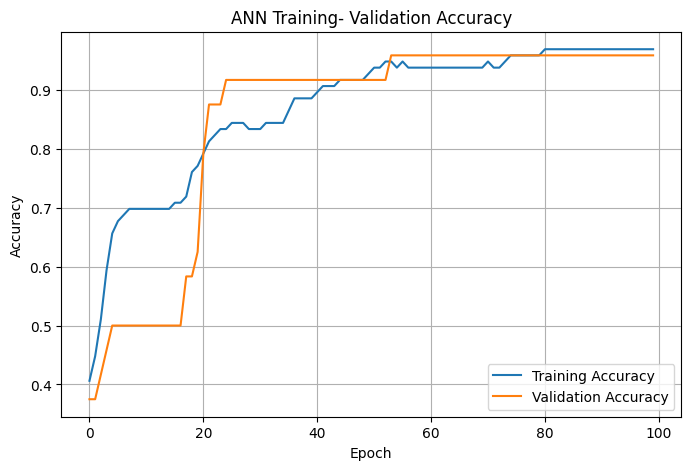

In [15]:
# ==========================================================
# 9. PLOT TRAINING AND VALIDATION ACCURACY
# ==========================================================

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("ANN Training- Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

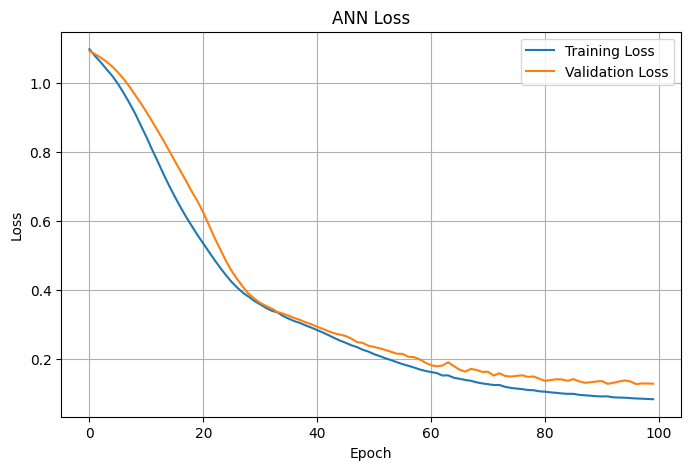

In [16]:
# ==========================================================
# 10. PLOT TRAINING AND VALIDATION LOSS
# ==========================================================

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("ANN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [17]:
# Predict a new flower
sample = [[5.1, 3.5, 1.4, 0.2]]

# Scale the sample
sample_scaled = scaler.transform(sample)

# Predict the class
prediction_probability = model.predict(sample_scaled)

print("\nPredicted Species:", prediction_probability)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step

Predicted Species: [[9.9693030e-01 3.0696471e-03 8.0223046e-08]]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [18]:
# Predict class label

predicted_class = np.argmax(prediction_probability, axis=1)[0]

# Convert numerical class back to original class name
predicted_label = encoder.inverse_transform([predicted_class])[0]

print("\n----------------------------------")
print("New Sample Prediction")
print("----------------------------------")

print("Input:", sample)
print("Predicted class:", predicted_label)

print("\nClass probabilities:")

for class_name, probability in zip(encoder.classes_,prediction_probability[0]):
    print(f"{class_name}: {probability:.4f}")


----------------------------------
New Sample Prediction
----------------------------------
Input: [[5.1, 3.5, 1.4, 0.2]]
Predicted class: setosa

Class probabilities:
setosa: 0.9969
versicolor: 0.0031
virginica: 0.0000
